# 10-amaliyot: seaborn bilan odatlar va imtihon natijasi

**Data Analysis kursi** · boshlang'ich–o'rta daraja · taxminiy vaqt: 110–120 daqiqa

Ma'lumot: `student_habits_performance.csv` — 1000 ta talabaning kundalik odatlari (o'qish, uyqu, ijtimoiy tarmoq, sport va h.k.) va imtihon bali.
**Asosiy savol: qaysi odat imtihon ballini eng ko'p belgilaydi?**

| Bo'lim | Mavzu | Asosiy funksiya |
|---|---|---|
| 1 | Tidy format va `hue` | `melt`, `sns.scatterplot` |
| 2 | Taqsimot: histogramma va zichlik 🆕 | `sns.histplot`, `sns.kdeplot` |
| 3 | Box plot: qo'lda va seaborn bilan | `quantile`, `sns.boxplot` |
| 4 | Violin va nuqtalar 🆕 | `sns.violinplot`, `sns.swarmplot`, `pd.cut` |
| 5 | Bog'liqlik: regressiya chizig'i 🆕 | `sns.regplot`, `sns.lmplot` |
| 6 | Heatmap va juft grafiklar 🆕 | `df.corr`, `sns.heatmap`, `sns.pairplot` |
| 7 | Sanash, o'rtacha, trend 🆕 | `sns.countplot`, `sns.barplot`, `sns.pointplot` |
| 8 | Panellar 🆕 | `sns.catplot`, `sns.displot` |
| 9 | Mini-loyiha: qaysi odat muhimroq? | hammasi birga |

🆕 — ma'ruzada bo'lmagan yangi grafik turlari. Har birini avval **Namuna**da ko'rasiz, keyin o'zingiz chizasiz.

### Qanday ishlaymiz
1. Har bir bo'lim **📘 Namuna** bilan boshlanadi — tayyor yechilgan. Ishga tushiring, grafikni ko'ring, kodni o'qing.
2. **🔹 Mashq** — `# Kodingizni shu yerga yozing` yoki `...` joyini to'ldiring.
3. **✅ Tekshirish** katakchasini ishga tushiring. `To'g'ri!` chiqsa — keyingisiga o'ting.
4. **🔍 Grafikni o'qing** mashqlarida grafikka qarab javob yozasiz.

> **Muhim:** `student_habits_performance.csv` fayli notebook bilan **bir papkada** bo'lsin.
> Axes-level grafiklarni `fig, ax = plt.subplots()` va `ax=ax` bilan chizing — tekshiruv aynan `ax` ga qaraydi.
> Figure-level grafiklar (`lmplot`, `pairplot`, `catplot`, `displot`) `ax=` olmaydi — natijani `g` ga saqlang.

### Ustunlar (qulaylik uchun nomlarini o'zbekchaga o'zgartirdik)

| Yangi nom | Asl nom | Ma'nosi | Qiymatlari |
|---|---|---|---|
| `yosh` | age | yosh | 17 – 24 |
| `jins` | gender | jins | `Female`, `Male`, `Other` |
| `oqish_soati` | study_hours_per_day | kuniga necha soat o'qiydi | 0 – 8.3 |
| `ijtimoiy_tarmoq` | social_media_hours | ijtimoiy tarmoqda (soat/kun) | 0 – 7.2 |
| `netflix` | netflix_hours | Netflix/kino ko'rishga (soat/kun) | 0 – 5.4 |
| `ish` | part_time_job | yarim kunlik ishi bormi | `Yes`, `No` |
| `davomat` | attendance_percentage | darslarga qatnashish, % | 56 – 100 |
| `uyqu` | sleep_hours | kuniga necha soat uxlaydi | 3.2 – 10 |
| `ovqat` | diet_quality | ovqatlanish sifati | `Poor`, `Fair`, `Good` |
| `sport` | exercise_frequency | haftada necha marta sport qiladi | 0 – 6 |
| `ota_ona_talimi` | parental_education_level | ota-onasining ta'limi | `High School`, `Bachelor`, `Master`, **bo'sh (91 ta)** |
| `internet` | internet_quality | internet sifati | `Poor`, `Average`, `Good` |
| `ruhiy_holat` | mental_health_rating | ruhiy holat bahosi | 1 – 10 |
| `togarak` | extracurricular_participation | to'garaklarda qatnashadimi | `Yes`, `No` |
| `ball` | exam_score | **imtihon bali (natija)** | 18.4 – 100 |

In [73]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (8, 4)

talaba = pd.read_csv('student_habits_performance.csv').rename(columns={
    'age': 'yosh', 'gender': 'jins', 'study_hours_per_day': 'oqish_soati',
    'social_media_hours': 'ijtimoiy_tarmoq', 'netflix_hours': 'netflix', 'part_time_job': 'ish',
    'attendance_percentage': 'davomat', 'sleep_hours': 'uyqu', 'diet_quality': 'ovqat',
    'exercise_frequency': 'sport', 'parental_education_level': 'ota_ona_talimi',
    'internet_quality': 'internet', 'mental_health_rating': 'ruhiy_holat',
    'extracurricular_participation': 'togarak', 'exam_score': 'ball'})

print(talaba.shape)
print("Bo'sh qiymatlar:", talaba.isna().sum()[talaba.isna().sum() > 0].to_dict())
talaba.head()

(1000, 16)
Bo'sh qiymatlar: {'ota_ona_talimi': 91}


,student_id,yosh,jins,oqish_soati,ijtimoiy_tarmoq,netflix,ish,davomat,uyqu,ovqat,sport,ota_ona_talimi,internet,ruhiy_holat,togarak,ball
0,S1000,23,Female,0.0,1.2,1.1,No,85.0,8.0,Fair,6,Master,Average,8,Yes,56.2
1,S1001,20,Female,6.9,2.8,2.3,No,97.3,4.6,Good,6,High School,Average,8,No,100.0
2,S1002,21,Male,1.4,3.1,1.3,No,94.8,8.0,Poor,1,High School,Poor,1,No,34.3
3,S1003,23,Female,1.0,3.9,1.0,No,71.0,9.2,Poor,4,Master,Good,1,Yes,26.8
4,S1004,19,Female,5.0,4.4,0.5,No,90.9,4.9,Fair,3,Master,Good,1,No,66.4


---
## 1. Tidy format va `hue`

Seaborn **uzun (tidy)** jadval bilan ishlaydi: har qatorda bitta kuzatuv, har ustunda bitta o'zgaruvchi.
`hue=` — uchinchi o'zgaruvchini **rang** bilan ko'rsatadi.

### 📘 Namuna 1

(8, 3)


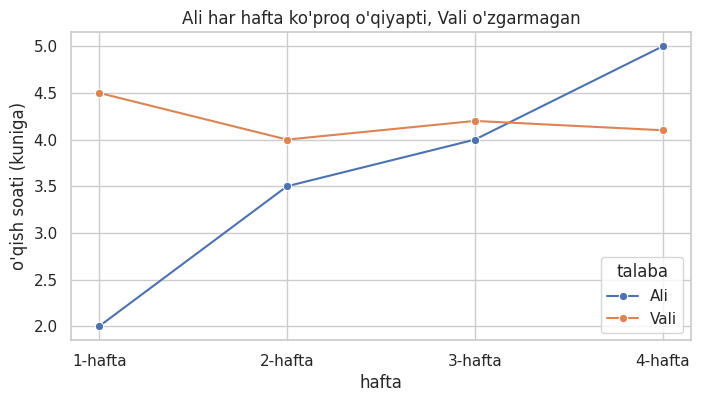

In [74]:
keng = pd.DataFrame({'hafta': ['1-hafta', '2-hafta', '3-hafta', '4-hafta'],
                     'Ali':  [2.0, 3.5, 4.0, 5.0],
                     'Vali': [4.5, 4.0, 4.2, 4.1]})
uzun = keng.melt(id_vars='hafta', var_name='talaba', value_name='soat')   # wide -> long
print(uzun.shape)          # (8, 3)

fig, ax = plt.subplots()
sns.lineplot(data=uzun, x='hafta', y='soat', hue='talaba', marker='o', ax=ax)
ax.set_title("Ali har hafta ko'proq o'qiyapti, Vali o'zgarmagan")
ax.set_ylabel("o'qish soati (kuniga)")
plt.show()

### 🔹 Mashq 1.1
To'rt talabaning kunlik vaqti (soat) **keng** jadvalda berilgan. Uni `melt` bilan uzun jadvalga aylantiring:
ustunlar `ism`, `faoliyat`, `soat` bo'lsin. Natijani `jurnal_uzun` ga saqlang.

In [75]:
jurnal = pd.DataFrame({'ism': ['Ali', 'Vali', 'Gani', 'Soli'],
                       'oqish':           [0.0, 6.9, 1.4, 1.0],
                       'ijtimoiy_tarmoq': [1.2, 2.8, 3.1, 3.9],
                       'netflix':         [1.1, 2.3, 1.3, 1.0]})

In [76]:
jurnal_uzun = jurnal.melt(
    id_vars='ism',
    var_name='faoliyat',
    value_name='soat'
)

jurnal_uzun

,ism,faoliyat,soat
0,Ali,oqish,0.0
1,Vali,oqish,6.9
2,Gani,oqish,1.4
3,Soli,oqish,1.0
4,Ali,ijtimoiy_tarmoq,1.2
5,Vali,ijtimoiy_tarmoq,2.8
6,Gani,ijtimoiy_tarmoq,3.1
7,Soli,ijtimoiy_tarmoq,3.9
8,Ali,netflix,1.1
9,Vali,netflix,2.3


In [77]:
# ✅ Tekshirish
assert jurnal_uzun.shape == (12, 3), f"O'lcham (12, 3) bo'lishi kerak, sizda: {jurnal_uzun.shape}"
assert list(jurnal_uzun.columns) == ['ism', 'faoliyat', 'soat'], "Ustunlar: ism, faoliyat, soat"
assert abs(jurnal_uzun['soat'].sum() - 26.0) < 1e-9
print("To'g'ri! 👍")

To'g'ri! 👍


### 🔹 Mashq 1.2
`talaba` jadvalidan `oqish_soati` ($x$) va `ball` ($y$) uchun **scatter** chizing, nuqtalar rangi — `jins` (`hue`).
Sarlavha va o'q nomlari bo'lsin.

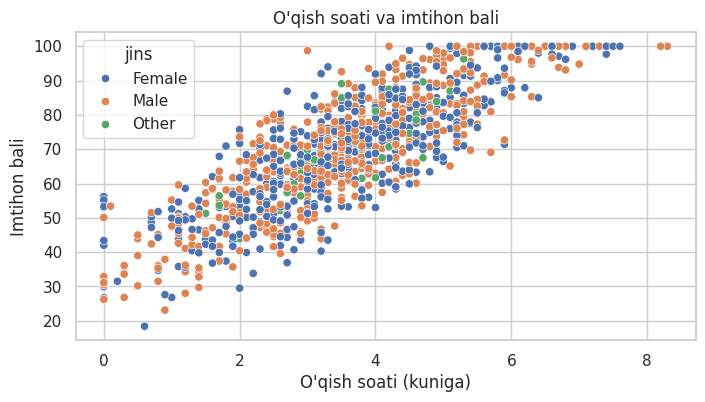

In [78]:
# Kodingizni shu yerga yozing
fig, ax = plt.subplots()

sns.scatterplot(
    data=talaba,
    x='oqish_soati',
    y='ball',
    hue='jins',
    ax=ax
)

ax.set_title("O'qish soati va imtihon bali")
ax.set_xlabel("O'qish soati (kuniga)")
ax.set_ylabel("Imtihon bali")

plt.show()

In [79]:
# ✅ Tekshirish
assert len(ax.collections) >= 1, "Scatter topilmadi: sns.scatterplot(..., ax=ax)"
assert sum(len(c.get_offsets()) for c in ax.collections) == 1000, "1000 ta nuqta bo'lishi kerak"
assert ax.get_legend() is not None, "hue='jins' bering — legend paydo bo'ladi"
assert ax.get_title() != '', "Sarlavha yozing"
print("To'g'ri! 👍")

To'g'ri! 👍


### 🔹 Mashq 1.3
`talaba` ning uchta vaqt ustunini (`oqish_soati`, `ijtimoiy_tarmoq`, `netflix`) `melt` bilan bitta uzun jadvalga aylantiring
(`value_vars=` dan foydalaning): ustunlar `faoliyat` va `soat` bo'lsin. Natijani `vaqt_uzun` ga saqlang.
Bunday jadval keyin uch faoliyatni **bitta grafikda** taqqoslashga kerak bo'ladi.

In [80]:
vaqt_uzun = talaba.melt(
    value_vars=['oqish_soati', 'ijtimoiy_tarmoq', 'netflix'],
    var_name='faoliyat',
    value_name='soat'
)

vaqt_uzun.head()

,faoliyat,soat
0,oqish_soati,0.0
1,oqish_soati,6.9
2,oqish_soati,1.4
3,oqish_soati,1.0
4,oqish_soati,5.0


In [81]:
# ✅ Tekshirish
assert vaqt_uzun.shape == (3000, 2), f"1000 talaba x 3 faoliyat = (3000, 2), sizda: {vaqt_uzun.shape}"
assert list(vaqt_uzun.columns) == ['faoliyat', 'soat'], "Ustunlar: faoliyat, soat"
assert round(vaqt_uzun['soat'].mean(), 2) == 2.63
print("To'g'ri! 👍")

To'g'ri! 👍


---
## 2. Taqsimot: `histplot` va `kdeplot` 🆕

**Qachon:** bitta sonli o'zgaruvchi **qanday taqsimlangan**ini ko'rish: qayerda zich, simmetrikmi, chekka qiymatlar bormi.
Bu — har qanday tahlilning **birinchi qadami**.

- `histplot` — qiymatlarni oraliqlarga (**bin**) bo'lib, har oraliqdagi sonni ustun bilan ko'rsatadi. `bins=` ustunlar soni, `kde=True` — ustiga silliq chiziq.
- `kdeplot` — silliqlangan zichlik chizig'i (violin ning "yarmi"). Bir necha guruhni **bir-biriga ustma-ust** qo'yib solishtirish qulay.
- Guruhlar soni teng bo'lmasa: `common_norm=False` (har guruh o'zi bilan normallashadi). Chegarali qiymatlar uchun `cut=0`.

### 📘 Namuna 2

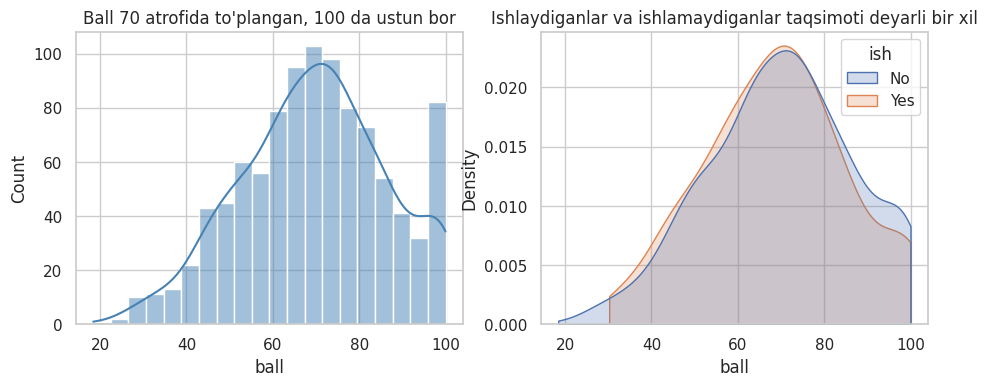

In [82]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(data=talaba, x='ball', bins=20, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title("Ball 70 atrofida to'plangan, 100 da ustun bor")

sns.kdeplot(data=talaba, x='ball', hue='ish', common_norm=False, fill=True, cut=0, ax=axes[1])
axes[1].set_title("Ishlaydiganlar va ishlamaydiganlar taqsimoti deyarli bir xil")
plt.show()

### 🔹 Mashq 2.1
`oqish_soati` ning **histogrammasini** chizing: `bins=20`, `kde=True`. Sarlavha yozing.

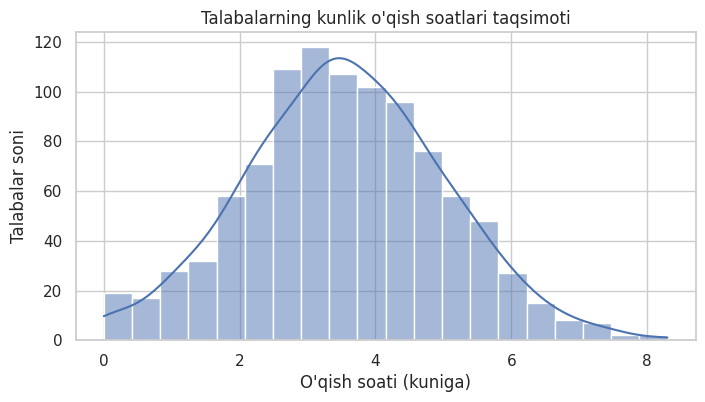

In [83]:
# Kodingizni shu yerga yozing
fig, ax = plt.subplots()

sns.histplot(
    data=talaba,
    x='oqish_soati',
    bins=20,
    kde=True,
    ax=ax
)

ax.set_title("Talabalarning kunlik o'qish soatlari taqsimoti")
ax.set_xlabel("O'qish soati (kuniga)")
ax.set_ylabel("Talabalar soni")

plt.show()

In [84]:
# ✅ Tekshirish
assert len(ax.patches) == 20, f"bins=20 -> 20 ta ustun bo'lishi kerak, sizda: {len(ax.patches)}"
assert len(ax.lines) >= 1, "kde=True bering — silliq chiziq paydo bo'ladi"
assert ax.get_title() != '', "Sarlavha yozing"
print("To'g'ri! 👍")

To'g'ri! 👍


### 🔹 Mashq 2.2
Uch faoliyat (o'qish, ijtimoiy tarmoq, Netflix) soatlarini **bitta** `kdeplot` da solishtiring. Buning uchun uzun jadval kerak — u tayyor (Mashq 1.3 dagi `melt`).
`x='soat'`, `hue='faoliyat'`, `fill=True`, `cut=0`, `common_norm=False`.

In [85]:
vaqt_uzun = talaba.melt(value_vars=['oqish_soati', 'ijtimoiy_tarmoq', 'netflix'], var_name='faoliyat', value_name='soat')

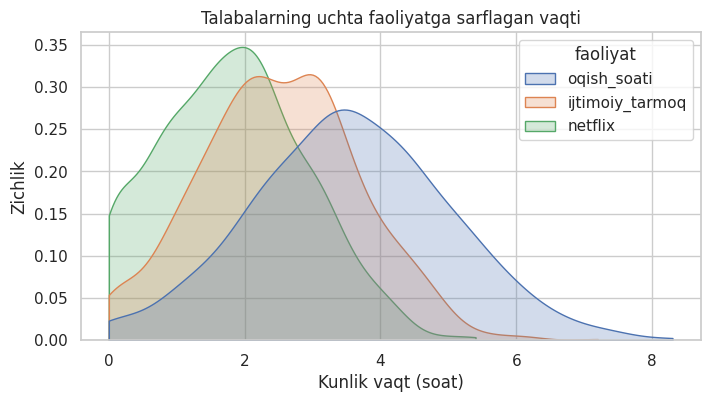

In [86]:
# Kodingizni shu yerga yozing
fig, ax = plt.subplots()

sns.kdeplot(
    data=vaqt_uzun,
    x='soat',
    hue='faoliyat',
    fill=True,
    cut=0,
    common_norm=False,
    ax=ax
)

ax.set_title("Talabalarning uchta faoliyatga sarflagan vaqti")
ax.set_xlabel("Kunlik vaqt (soat)")
ax.set_ylabel("Zichlik")

plt.show()

In [87]:
# ✅ Tekshirish
from matplotlib.collections import PolyCollection
polys = [c for c in ax.collections if isinstance(c, PolyCollection)]
assert len(polys) == 3, f"3 faoliyat -> 3 ta zichlik shakli bo'lishi kerak, sizda: {len(polys)}"
xmax = max(p.get_paths()[0].vertices[:, 0].max() for p in polys)
assert xmax <= vaqt_uzun['soat'].max() + 1e-6, "cut=0 bering — chiziq ma'lumot chegarasidan chiqmasin"
assert ax.get_legend() is not None, "hue='faoliyat' bering"
print("To'g'ri! 👍")

To'g'ri! 👍


### 🔍 Mashq 2.3 — grafikni o'qing va kod bilan tekshiring
Namuna 2 dagi histogrammaga qarang.
- `javob_2a` — ballar eng ko'p qaysi **10 balllik oraliqda**? (`'60-70'`, `'70-80'` yoki `'80-90'`)
- `javob_2b` — grafikning o'ng chetidagi balandroq ustunni nima tushuntiradi? Aniq **100 ball** olganlar nechta? (kod bilan sanang)

In [88]:
javob_2a = '70-80'
javob_2b = (talaba['ball'] == 100).sum()

print("Eng ko'p ball to'plangan oraliq:", javob_2a)
print("100 ball olgan talabalar soni:", javob_2b)

Eng ko'p ball to'plangan oraliq: 70-80
100 ball olgan talabalar soni: 48


In [89]:
# ✅ Tekshirish
assert javob_2a == '70-80', "Qaysi oraliqda ustun eng baland? (np.histogram bilan ham sanash mumkin)"
assert javob_2b == 48, f"100 ball olganlar soni 48 bo'lishi kerak, sizda: {javob_2b}"
print("To'g'ri! 👍  48 kishi aynan 100 olgan: ball 100 bilan 'kesilgan', shuning uchun o'ng chetda ustun hosil bo'ladi.")

To'g'ri! 👍  48 kishi aynan 100 olgan: ball 100 bilan 'kesilgan', shuning uchun o'ng chetda ustun hosil bo'ladi.


---
## 3. Box plot

**Qachon:** bitta sonli o'zgaruvchini **guruhlar** bo'yicha taqqoslash — median, tarqoqlik, outlier.
Quti — $Q_1$ dan $Q_3$ gacha (o'rtadagi 50%), chiziq — median, **whisker** — $1.5\times IQR$ chegarasi ichidagi
eng chekka qiymat, undan tashqaridagilar — **outlier**.

### 📘 Namuna 3 — qo'lda hisoblash

Q1=61.0, median=70.0, Q3=77.5, IQR=16.5
chegaralar: 36.25 ... 102.25
outlierlar: [34, 150]
whiskerlar: 55 va 84


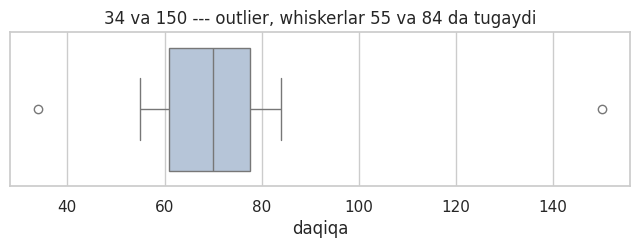

In [90]:
daqiqa = pd.Series([34, 55, 60, 62, 65, 70, 72, 75, 80, 84, 150])    # telefonda o'tkazilgan vaqt, daqiqa

q1, med, q3 = daqiqa.quantile([0.25, 0.5, 0.75])
iqr = q3 - q1
past, yuqori = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f"Q1={q1}, median={med}, Q3={q3}, IQR={iqr}")
print(f"chegaralar: {past} ... {yuqori}")
print("outlierlar:", list(daqiqa[(daqiqa < past) | (daqiqa > yuqori)]))
print("whiskerlar:", daqiqa[daqiqa >= past].min(), 'va', daqiqa[daqiqa <= yuqori].max())

fig, ax = plt.subplots(figsize=(8, 2))
sns.boxplot(x=daqiqa, ax=ax, color='lightsteelblue')
ax.set_title("34 va 150 --- outlier, whiskerlar 55 va 84 da tugaydi")
ax.set_xlabel('daqiqa')
plt.show()

### 🔹 Mashq 3.1
13 ta talabaning kuniga ijtimoiy tarmoqda o'tkazgan vaqti (daqiqa) berilgan. Namunadagidek hisoblang:
`q1_s`, `q3_s`, `iqr_s`, `yuqori_s` (**yuqori** chegara) va `outlier_s` (outlier qiymatlar ro'yxati).

In [91]:
vaqt = pd.Series([95, 100, 70, 240, 62, 85, 10, 110, 74, 300, 55, 90, 80])

In [92]:
q1_s = vaqt.quantile(0.25)
q3_s = vaqt.quantile(0.75)

iqr_s = q3_s - q1_s

yuqori_s = q3_s + 1.5 * iqr_s
pastki_s = q1_s - 1.5 * iqr_s

outlier_s = vaqt[(vaqt < pastki_s) | (vaqt > yuqori_s)].tolist()

print("Q1:", q1_s)
print("Q3:", q3_s)
print("IQR:", iqr_s)
print("Yuqori chegara:", yuqori_s)
print("Outlierlar:", outlier_s)

Q1: 70.0
Q3: 100.0
IQR: 30.0
Yuqori chegara: 145.0
Outlierlar: [240, 10, 300]


In [93]:
# ✅ Tekshirish
assert (q1_s, q3_s) == (70.0, 100.0), f"Q1 va Q3 noto'g'ri: {q1_s}, {q3_s}"
assert iqr_s == 30.0 and yuqori_s == 145.0, "IQR = Q3 - Q1; yuqori chegara = Q3 + 1.5*IQR"
assert sorted(outlier_s) == [10, 240, 300], f"Outlierlar (pastdagi ham, yuqoridagi ham): {outlier_s}"
print("To'g'ri! 👍  Pastki chegara (25) dan past ham, yuqori chegara (145) dan baland ham outlier hisoblanadi.")

To'g'ri! 👍  Pastki chegara (25) dan past ham, yuqori chegara (145) dan baland ham outlier hisoblanadi.


### 🔹 Mashq 3.2
`talaba` jadvalida **haftada necha marta sport qilishiga (`sport`) qarab ball** box plotini chizing: `x='sport'`, `y='ball'`.

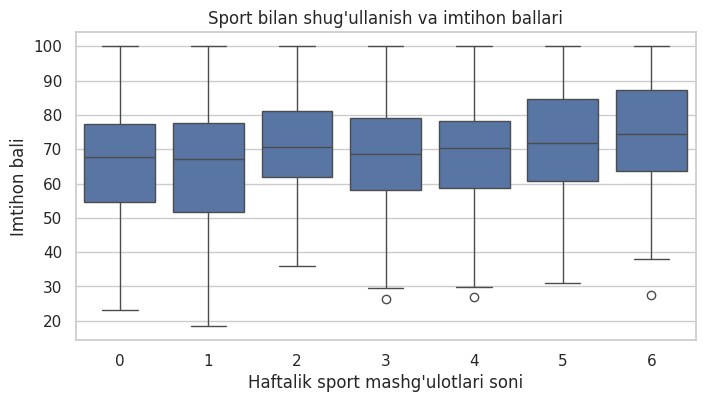

In [94]:
# Kodingizni shu yerga yozing
fig, ax = plt.subplots()

sns.boxplot(
    data=talaba,
    x='sport',
    y='ball',
    order=[0, 1, 2, 3, 4, 5, 6],
    ax=ax
)

ax.set_title("Sport bilan shug'ullanish va imtihon ballari")
ax.set_xlabel("Haftalik sport mashg'ulotlari soni")
ax.set_ylabel("Imtihon bali")

plt.show()

In [95]:
# ✅ Tekshirish
assert len(ax.patches) >= 7, f"sport 0 dan 6 gacha -> 7 ta quti bo'lishi kerak, sizda: {len(ax.patches)}"
assert [t.get_text() for t in ax.get_xticklabels()] == ['0', '1', '2', '3', '4', '5', '6'], "x='sport' bering"
print("To'g'ri! 👍")

To'g'ri! 👍


### 🔍 Mashq 3.3 — grafikni o'qing va kod bilan tekshiring
- `javob_3a` — **median** ball haftada necha marta sport qiladiganlarda eng yuqori? (son)
- `javob_3b` — barcha 7 ta qutida jami nechta **outlier** nuqta bor? Namuna 3 dagi qoidani har bir guruhga qo'llang.

In [96]:
javob_3a = int(talaba.groupby('sport')['ball'].median().idxmax())

javob_3b = 0

for sport, guruh in talaba.groupby('sport'):
    q1 = guruh['ball'].quantile(0.25)
    q3 = guruh['ball'].quantile(0.75)
    iqr = q3 - q1

    pastki = q1 - 1.5 * iqr
    yuqori = q3 + 1.5 * iqr

    javob_3b += int(
        ((guruh['ball'] < pastki) | (guruh['ball'] > yuqori)).sum()
    )

print("Eng yuqori median sport guruhi:", javob_3a)
print("Jami outlierlar soni:", javob_3b)

Eng yuqori median sport guruhi: 6
Jami outlierlar soni: 3


In [97]:
# ✅ Tekshirish
assert javob_3a == 6, "Qutilar ichidagi chiziq qaysi sport kunida eng baland?"
assert javob_3b == 3, f"Jami 3 ta outlier bo'lishi kerak, sizda: {javob_3b}"
print("To'g'ri! 👍")

To'g'ri! 👍


---
## 4. Violin va nuqtalar: `violinplot`, `swarmplot` 🆕

**Violin — qachon:** guruhlarda kuzatuv **ko'p** va taqsimotning **shakli** (nechta cho'qqi, qayerda zich) muhim bo'lganda.
Violin — ikki tomonga aks ettirilgan silliq histogramma. Chegarali qiymatlar (ball, foiz, soat) uchun `cut=0`.

**Swarm — qachon:** har bir kuzatuvni **alohida nuqta** sifatida ko'rsatish (nuqtalar bir-birini bosmaydi). Kuzatuv kam bo'lganda, yoki violin ustiga qo'yib,
"bu shakl nechta nuqtadan qurilgan" ni ko'rsatish uchun juda yaxshi. Ko'p ma'lumotda (1000+) sekin va to'lib ketadi — shuning uchun `sample` bilan kichraytiramiz.

Avval ruhiy holatni (1–10) **uch toifaga** bo'lamiz — buning uchun `pd.cut` ishlatiladi:

In [98]:
# pd.cut: sonlarni oraliqlarga bo'lib, toifa (kategoriya) ustuni yasaydi. Oraliqlar: (0,3], (3,7], (7,10]
talaba['ruhiy_toifa'] = pd.cut(talaba['ruhiy_holat'], bins=[0, 3, 7, 10], labels=['past', "o'rta", 'yuqori'])
talaba['ruhiy_toifa'].value_counts().sort_index()

,count
ruhiy_toifa,
past,301
o'rta,408
yuqori,291


### 📘 Namuna 4

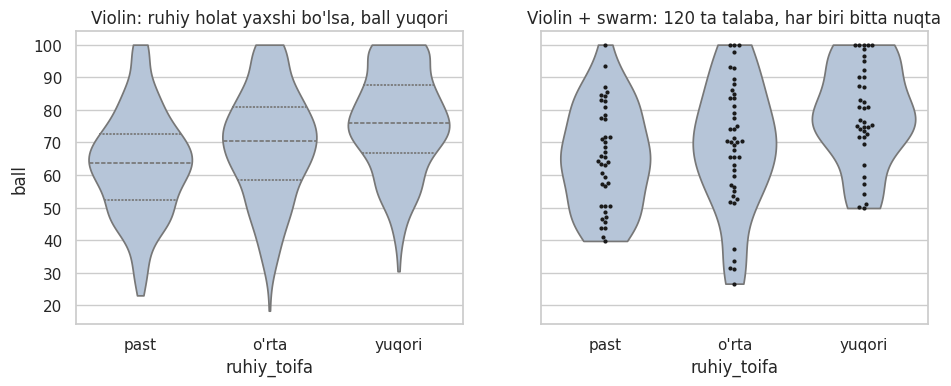

In [99]:
kichik_namuna = talaba.sample(120, random_state=3)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
sns.violinplot(data=talaba, x='ruhiy_toifa', y='ball', ax=axes[0], inner='quart', cut=0, color='lightsteelblue')
axes[0].set_title("Violin: ruhiy holat yaxshi bo'lsa, ball yuqori")

sns.violinplot(data=kichik_namuna, x='ruhiy_toifa', y='ball', ax=axes[1], inner=None, cut=0, color='lightsteelblue')
sns.swarmplot(data=kichik_namuna, x='ruhiy_toifa', y='ball', ax=axes[1], color='k', size=3)
axes[1].set_title("Violin + swarm: 120 ta talaba, har biri bitta nuqta")
plt.show()

### 🔹 Mashq 4.1
Ikki panelli rasm chizing (`fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))`), ikkalasida `x='ruhiy_toifa'`, `inner='quart'`, `cut=0`:
- chapda `ball` ning violini,
- o'ngda `oqish_soati` ning violini.

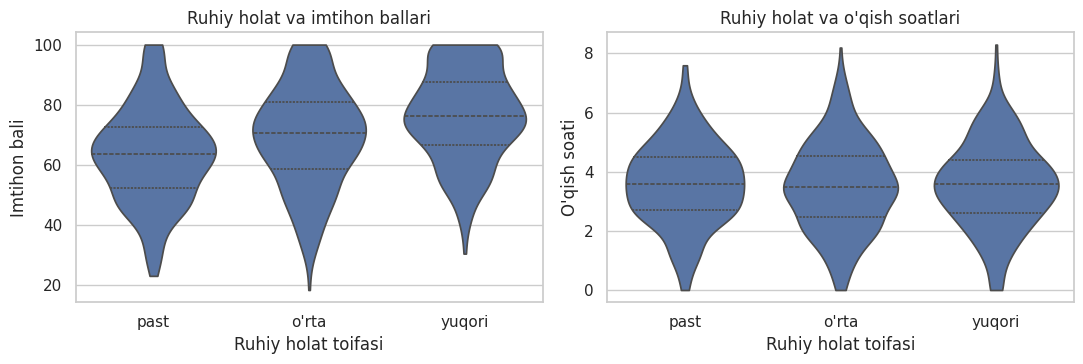

In [100]:
# Kodingizni shu yerga yozing
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

sns.violinplot(
    data=talaba,
    x='ruhiy_toifa',
    y='ball',
    inner='quart',
    cut=0,
    ax=axes[0]
)

axes[0].set_title("Ruhiy holat va imtihon ballari")
axes[0].set_xlabel("Ruhiy holat toifasi")
axes[0].set_ylabel("Imtihon bali")

sns.violinplot(
    data=talaba,
    x='ruhiy_toifa',
    y='oqish_soati',
    inner='quart',
    cut=0,
    ax=axes[1]
)

axes[1].set_title("Ruhiy holat va o'qish soatlari")
axes[1].set_xlabel("Ruhiy holat toifasi")
axes[1].set_ylabel("O'qish soati")

plt.tight_layout()
plt.show()

In [101]:
# ✅ Tekshirish
from matplotlib.collections import PolyCollection
for ax_, ustun in zip(axes, ['ball', 'oqish_soati']):
    polys = [c for c in ax_.collections if isinstance(c, PolyCollection)]
    assert len(polys) == 3, f"Har panelda 3 ta violin bo'lishi kerak, sizda: {len(polys)}"
    ymin = min(p.get_paths()[0].vertices[:, 1].min() for p in polys)
    assert ymin >= talaba[ustun].min() - 1e-6, "cut=0 bering — violin ma'lumot chegarasidan chiqmasin"
print("To'g'ri! 👍")

To'g'ri! 👍


### 🔍 Mashq 4.2 — grafikni o'qing
Mashq 4.1 dagi ikki violinga qarang.
- `javob_4a` — qaysi ruhiy toifada **median** ball eng yuqori? (`'past'`, `"o'rta"` yoki `'yuqori'`)
- `javob_4b` — o'qish soati taqsimoti ruhiy toifalar bo'yicha **farq qiladimi**? (`True` / `False`)

In [102]:
javob_4a = talaba.groupby(
    'ruhiy_toifa',
    observed=True
)['ball'].median().idxmax()

javob_4b = False

print("Eng yuqori median ball:", javob_4a)
print("O'qish soatlari taqsimoti farqlanadimi:", javob_4b)

Eng yuqori median ball: yuqori
O'qish soatlari taqsimoti farqlanadimi: False


In [103]:
# ✅ Tekshirish
assert javob_4a == 'yuqori', "Chapdagi violinlarda ichki o'rta chiziq qaysi birida eng baland?"
assert javob_4b is False, "O'ngdagi uch violinning shakli va o'rta chiziqlarini solishtiring"
print("To'g'ri! 👍  Ruhiy holat ball bilan bog'liq, lekin o'qish soati bilan deyarli bog'liq emas (r ≈ 0.00).")

To'g'ri! 👍  Ruhiy holat ball bilan bog'liq, lekin o'qish soati bilan deyarli bog'liq emas (r ≈ 0.00).


### 🔹 Mashq 4.3
Violin ustiga swarm qo'shing. Avval tayyor `kichik = talaba.sample(90, random_state=7)` ni oling, so'ng **bitta** `ax` ga:
1. `violinplot`: `x='ruhiy_toifa'`, `y='ball'`, `inner=None`, `cut=0`, `color='lightsteelblue'`;
2. `swarmplot`: xuddi shu ma'lumot, `color='k'`, `size=3`.

In [104]:
kichik = talaba.sample(90, random_state=7)

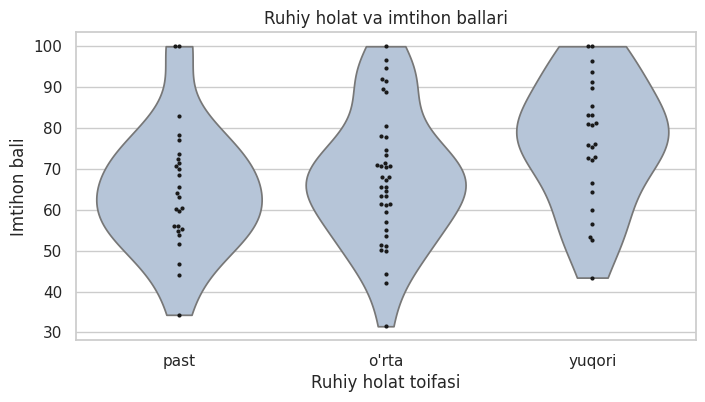

In [105]:
# Kodingizni shu yerga yozing
fig, ax = plt.subplots()

sns.violinplot(
    data=kichik,
    x='ruhiy_toifa',
    y='ball',
    inner=None,
    cut=0,
    color='lightsteelblue',
    ax=ax
)

sns.swarmplot(
    data=kichik,
    x='ruhiy_toifa',
    y='ball',
    color='k',
    size=3,
    ax=ax
)

ax.set_title("Ruhiy holat va imtihon ballari")
ax.set_xlabel("Ruhiy holat toifasi")
ax.set_ylabel("Imtihon bali")

plt.show()

In [106]:
# ✅ Tekshirish
from matplotlib.collections import PolyCollection
polys = [c for c in ax.collections if isinstance(c, PolyCollection)]
nuqta = sum(len(c.get_offsets()) for c in ax.collections if not isinstance(c, PolyCollection))
assert len(polys) == 3, f"3 ta violin bo'lishi kerak, sizda: {len(polys)}"
assert nuqta == 90, f"90 ta nuqta (swarmplot) bo'lishi kerak, sizda: {nuqta}"
print("To'g'ri! 👍")

To'g'ri! 👍


---
## 5. Bog'liqlik: `regplot` va `lmplot` 🆕

**Qachon:** **ikki sonli** o'zgaruvchi orasidagi bog'liqlikni ko'rish va uning **yo'nalishi** va **kuchini** baholash.
Scatter nuqtalarni ko'rsatadi, `regplot` esa ularga **to'g'ri chiziq** (regressiya) va uning 95% ishonch oralig'ini (soya) qo'shadi.
Chiziqning qiyaligi: $x$ 1 birlikka oshganda $y$ o'rtacha qanchaga o'zgaradi.

- `regplot` — axes-level (`ax=ax` oladi).
- `lmplot` — figure-level: `hue=` bilan guruhlar uchun **alohida chiziqlar**, `col=` bilan panellar. `ax=` olmaydi, natija — `g`.

### 📘 Namuna 5

Har qo'shimcha o'qish soati ballni o'rtacha 9.5 ga oshiradi


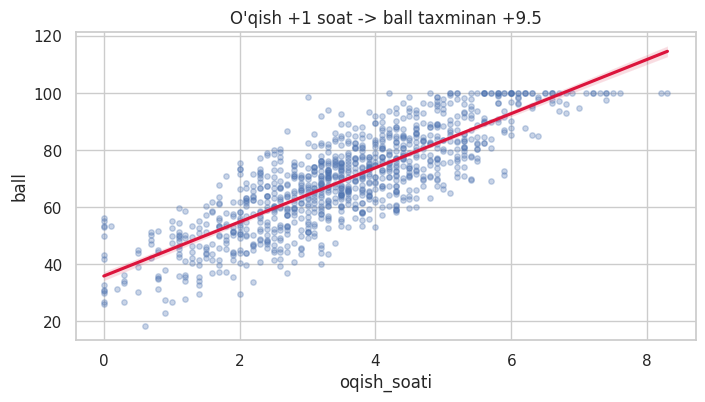

In [107]:
qiyalik, kesim = np.polyfit(talaba['oqish_soati'], talaba['ball'], 1)   # to'g'ri chiziq: ball = qiyalik * soat + kesim
print(f"Har qo'shimcha o'qish soati ballni o'rtacha {qiyalik:.1f} ga oshiradi")

fig, ax = plt.subplots()
sns.regplot(data=talaba, x='oqish_soati', y='ball', scatter_kws={'alpha': 0.3, 's': 15}, line_kws={'color': 'crimson'}, ax=ax)
ax.set_title(f"O'qish +1 soat -> ball taxminan +{qiyalik:.1f}")
plt.show()

### 🔹 Mashq 5.1
`ijtimoiy_tarmoq` ($x$) va `ball` ($y$) uchun `regplot` chizing: `scatter_kws={'alpha': 0.3, 's': 15}`. Sarlavha yozing.

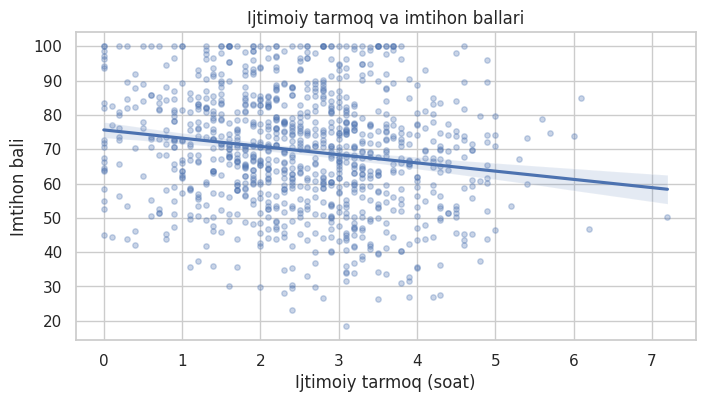

In [108]:
# Kodingizni shu yerga yozing
fig, ax = plt.subplots()

sns.regplot(
    data=talaba,
    x='ijtimoiy_tarmoq',
    y='ball',
    scatter_kws={'alpha': 0.3, 's': 15},
    ax=ax
)

ax.set_title("Ijtimoiy tarmoq va imtihon ballari")
ax.set_xlabel("Ijtimoiy tarmoq (soat)")
ax.set_ylabel("Imtihon bali")

plt.show()

In [109]:
# ✅ Tekshirish
assert len(ax.collections[0].get_offsets()) == 1000, "1000 ta nuqta bo'lishi kerak: sns.regplot(..., ax=ax)"
x_, y_ = ax.lines[0].get_data()
qiyalik_ = (y_[-1] - y_[0]) / (x_[-1] - x_[0])
assert abs(qiyalik_ - (-2.40)) < 0.05, f"Chiziq qiyaligi taxminan -2.40 bo'lishi kerak, sizda: {qiyalik_:.2f}"
assert ax.get_title() != '', "Sarlavha yozing"
print("To'g'ri! 👍")

To'g'ri! 👍


### 🔹 Mashq 5.2
`lmplot` bilan `oqish_soati` ($x$) va `ball` ($y$) bog'liqligini **ish bor/yo'q** (`hue='ish'`) bo'yicha ikki chiziq bilan chizing.
`scatter_kws={'alpha': 0.3, 's': 15}`, `height=4`. Natijani `g` ga saqlang.

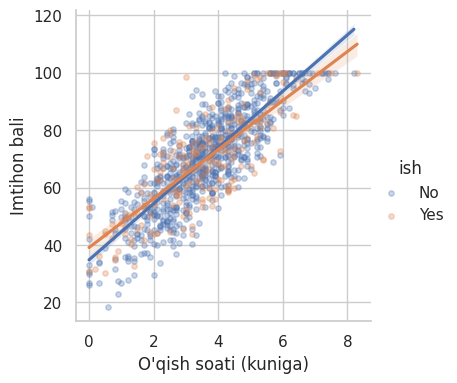

In [110]:
g = sns.lmplot(
    data=talaba,
    x='oqish_soati',
    y='ball',
    hue='ish',
    scatter_kws={'alpha': 0.3, 's': 15},
    height=4
)

g.set_axis_labels("O'qish soati (kuniga)", "Imtihon bali")

plt.show()

In [111]:
# ✅ Tekshirish
assert g.axes.shape == (1, 1), "col= bermang — bitta panel bo'lishi kerak"
assert len(g.ax.lines) == 2, f"hue='ish' -> 2 ta chiziq bo'lishi kerak, sizda: {len(g.ax.lines)}"
assert g.legend is not None, "hue='ish' bering — legend paydo bo'ladi"
print("To'g'ri! 👍")

To'g'ri! 👍


### 🔍 Mashq 5.3 — grafikni o'qing va kod bilan tekshiring
- `javob_5a` — o'qish kuniga **1 soatga oshsa**, ball o'rtacha taxminan nechaga oshadi? Variantlar: `1`, `5`, `10`, `20`.
- `javob_5b` — ijtimoiy tarmoqdagi soat oshsa, ball `'oshadi'` yoki `'kamayadi'`?
- `javob_5c` — Mashq 5.2 da ish bor va ish yo'q talabalar uchun chiziqlar deyarli **bir xil**mi? (`True` / `False`)

In [112]:
javob_5a = 10
javob_5b = 'kamayadi'
javob_5c = True

print("O'qish 1 soat oshsa, ball taxminan:", javob_5a)
print("Ijtimoiy tarmoq vaqti oshsa, ball:", javob_5b)
print("Ikki guruh chiziqlari deyarli bir xilmi:", javob_5c)

O'qish 1 soat oshsa, ball taxminan: 10
Ijtimoiy tarmoq vaqti oshsa, ball: kamayadi
Ikki guruh chiziqlari deyarli bir xilmi: True


In [113]:
# ✅ Tekshirish
assert javob_5a == 10, "Namuna 5 sarlavhasiga yoki np.polyfit natijasiga qarang: ~9.5 ga eng yaqin variant?"
assert javob_5b == 'kamayadi', "Mashq 5.1 dagi chiziq pastga qarab ketadimi?"
assert javob_5c is True, "Ikki rangli chiziq ustma-ust tushadimi?"
print("To'g'ri! 👍  Ish bor-yo'qligi o'qish-ball munosabatini deyarli o'zgartirmaydi.")

To'g'ri! 👍  Ish bor-yo'qligi o'qish-ball munosabatini deyarli o'zgartirmaydi.


---
## 6. Heatmap va `pairplot` 🆕

**Heatmap — qachon:** ko'p sonli ustunlar orasidagi bog'liqlikni **bir qarashda** ko'rish.
Korrelyatsiya $-1$ dan $+1$ gacha — shuning uchun **ikki tomonlama** palitra (`RdBu_r`), `center=0`, `vmin=-1`, `vmax=1`.

**pairplot — qachon:** bir nechta ustunning **hamma juftligini** scatter bilan ko'rish (diagonalda har birining taqsimoti).
Heatmap faqat bitta son (r) beradi, `pairplot` esa bog'liqlikning **shaklini** ko'rsatadi: to'g'ri chiziqmi, egrimi, outlier bormi.
Figure-level, natija — `g`. `corner=True` — takrorlanuvchi yuqori uchburchakni olib tashlaydi.

### 📘 Namuna 6

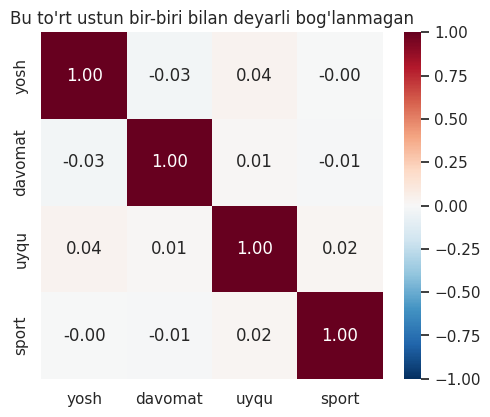

In [114]:
C = talaba[['yosh', 'davomat', 'uyqu', 'sport']].corr()

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(C, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Bu to'rt ustun bir-biri bilan deyarli bog'lanmagan")
plt.show()

### 🔹 Mashq 6.1
`talaba` jadvalining **9 ta sonli** ustuni (`yosh`, `oqish_soati`, `ijtimoiy_tarmoq`, `netflix`, `davomat`, `uyqu`, `sport`, `ruhiy_holat`, `ball`) uchun
korrelyatsiya matritsasini `C_talaba` ga hisoblang va heatmap chizing:
- `annot=True`, `fmt='.2f'`, `cmap='RdBu_r'`, `center=0`, `vmin=-1`, `vmax=1`;
- takrorlanuvchi **yuqori uchburchakni** yashiring: `mask=np.triu(np.ones_like(C_talaba, dtype=bool))`.

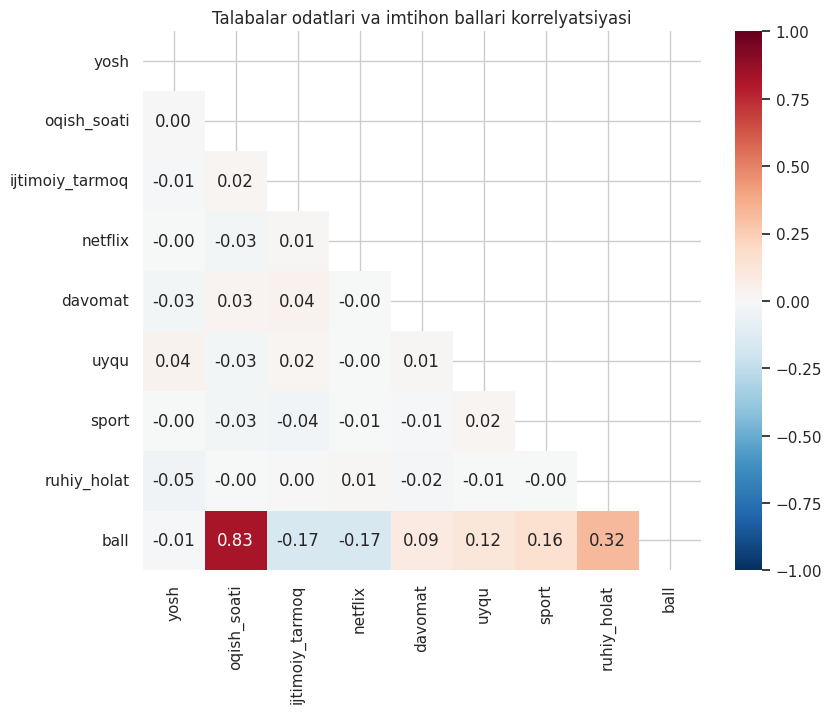

In [115]:
# Kodingizni shu yerga yozing
sonli = [
    'yosh', 'oqish_soati', 'ijtimoiy_tarmoq',
    'netflix', 'davomat', 'uyqu',
    'sport', 'ruhiy_holat', 'ball'
]

C_talaba = talaba[sonli].corr()

fig, ax = plt.subplots(figsize=(9, 7))

mask = np.triu(
    np.ones_like(C_talaba, dtype=bool)
)

sns.heatmap(
    C_talaba,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    center=0,
    vmin=-1,
    vmax=1,
    mask=mask,
    ax=ax
)

ax.set_title("Talabalar odatlari va imtihon ballari korrelyatsiyasi")

plt.show()

In [116]:
# ✅ Tekshirish
assert C_talaba.shape == (9, 9), "9 ta sonli ustun -> 9x9 matritsa"
assert len(ax.texts) == 36, f"Niqob bilan faqat 36 ta katakda son qolishi kerak, sizda: {len(ax.texts)}"
assert np.allclose(ax.collections[0].get_cmap()(0.0), plt.get_cmap('RdBu_r')(0.0)) and \
       np.allclose(ax.collections[0].get_cmap()(1.0), plt.get_cmap('RdBu_r')(1.0)), "cmap='RdBu_r' bering"
assert ax.collections[0].get_clim() == (-1, 1), "vmin=-1, vmax=1 bering"
print("To'g'ri! 👍")

To'g'ri! 👍


### 🔍 Mashq 6.2 — grafikni o'qing
- `javob_6a` — eng kuchli **musbat** bog'langan juftlik (ikki ustun nomi, `set` ko'rinishida, masalan `{'sport', 'ball'}`);
- `javob_6b` — `ball` bilan **manfiy** bog'langan (r ≈ -0.17) ikkita ustun (`set`).

In [117]:
javob_6a = {'oqish_soati', 'ball'}

javob_6b = {'ijtimoiy_tarmoq', 'netflix'}

print("Eng kuchli musbat bog'liqlik:", javob_6a)
print("Ball bilan manfiy bog'langan ustunlar:", javob_6b)

Eng kuchli musbat bog'liqlik: {'oqish_soati', 'ball'}
Ball bilan manfiy bog'langan ustunlar: {'netflix', 'ijtimoiy_tarmoq'}


In [118]:
# ✅ Tekshirish
assert javob_6a == {'oqish_soati', 'ball'}, "Eng to'q qizil katak qaysi? (diagonal hisobga olinmaydi)"
assert javob_6b == {'ijtimoiy_tarmoq', 'netflix'}, "'ball' qatoridagi ko'k kataklar qaysi ustunlarga to'g'ri keladi?"
print("To'g'ri! 👍  Esda tuting: korrelyatsiya sabab-oqibatni isbotlamaydi.")

To'g'ri! 👍  Esda tuting: korrelyatsiya sabab-oqibatni isbotlamaydi.


### 📘 Namuna 6b — `pairplot`

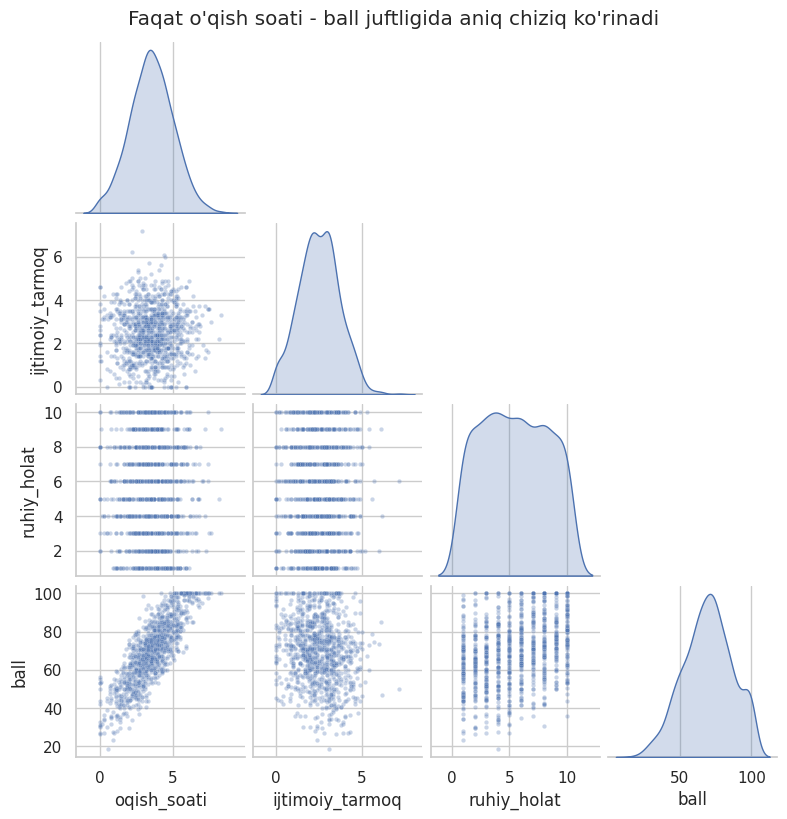

In [119]:
g = sns.pairplot(talaba, vars=['oqish_soati', 'ijtimoiy_tarmoq', 'ruhiy_holat', 'ball'],
                 corner=True, diag_kind='kde', height=2, plot_kws={'alpha': 0.3, 's': 10})
g.figure.suptitle("Faqat o'qish soati - ball juftligida aniq chiziq ko'rinadi", y=1.02)
plt.show()

### 🔹 Mashq 6.3
`pairplot` bilan `oqish_soati`, `netflix`, `ball` uchun juft grafiklarni chizing: `corner=True`, `kind='reg'` (har juftlikka regressiya chizig'i),
`plot_kws={'scatter_kws': {'alpha': 0.3, 's': 10}}`, `height=2.2`. Natijani `g3` ga saqlang.

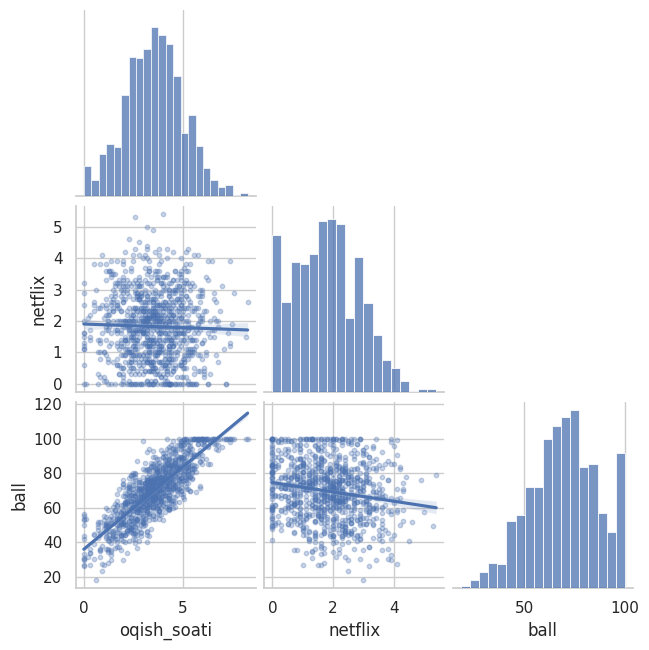

In [120]:
g3 = sns.pairplot(
    talaba,
    vars=['oqish_soati', 'netflix', 'ball'],
    corner=True,
    kind='reg',
    plot_kws={
        'scatter_kws': {'alpha': 0.3, 's': 10}
    },
    height=2.2
)

plt.show()

In [121]:
# ✅ Tekshirish
assert g3.axes.shape == (3, 3), "3 ta ustun -> 3x3 panel"
qolgan = sum(a is not None for a in g3.axes.flat)
assert qolgan == 6, f"corner=True bilan 6 ta panel qolishi kerak (diagonal + pastki uchburchak), sizda: {qolgan}"
print("To'g'ri! 👍")

To'g'ri! 👍


---
## 7. Sanash, o'rtacha va trend: `countplot`, `barplot`, `pointplot` 🆕

- `countplot` — **qatorlarni sanaydi** (`value_counts` + bar). $y$ ga son berilmaydi.
- `barplot` — har guruhning **o'rtachasi** va uning **95% ishonch oralig'i** (qora chiziq).
- `pointplot` — xuddi `barplot` kabi o'rtacha + ishonch oralig'i, lekin **nuqta + chiziq** bilan. Guruhlar **tartiblangan** bo'lsa (0,1,2,… yoki past → yuqori), **trend** (o'sish, pasayish)ni ko'rsatishda barplotdan yaxshi.

### 📘 Namuna 7

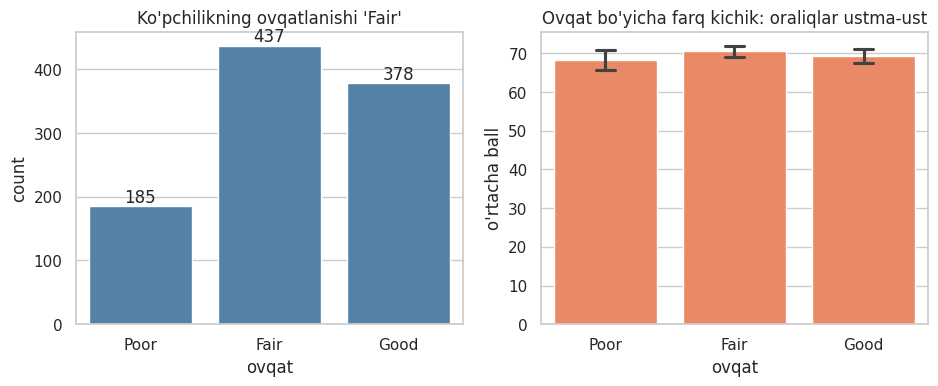

In [122]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.countplot(data=talaba, x='ovqat', order=['Poor', 'Fair', 'Good'], ax=axes[0], color='steelblue')
axes[0].set_title("Ko'pchilikning ovqatlanishi 'Fair'")
for c in axes[0].containers:
    axes[0].bar_label(c)

sns.barplot(data=talaba, x='ovqat', y='ball', order=['Poor', 'Fair', 'Good'], errorbar=('ci', 95), capsize=0.15, ax=axes[1], color='coral')
axes[1].set_title("Ovqat bo'yicha farq kichik: oraliqlar ustma-ust")
axes[1].set_ylabel("o'rtacha ball")
plt.show()

### 🔹 Mashq 7.1
`ota_ona_talimi` bo'yicha talabalar sonini **gorizontal** countplot bilan chizing (`y='ota_ona_talimi'`),
eng ko'pi tepada bo'lsin (`order=...value_counts().index`). Har ustunga son yozing (`bar_label`).

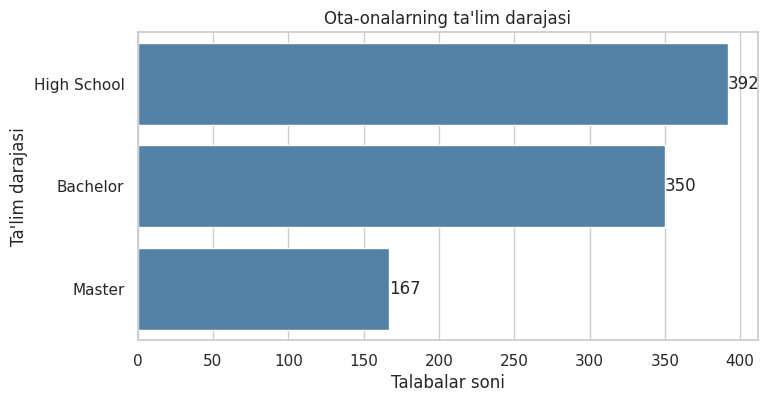

In [123]:
# Kodingizni shu yerga yozing
fig, ax = plt.subplots()

tartib = talaba['ota_ona_talimi'].value_counts().index

sns.countplot(
    data=talaba,
    y='ota_ona_talimi',
    order=tartib,
    color='steelblue',
    ax=ax
)

for container in ax.containers:
    ax.bar_label(container)

ax.set_title("Ota-onalarning ta'lim darajasi")
ax.set_xlabel("Talabalar soni")
ax.set_ylabel("Ta'lim darajasi")

plt.show()

In [124]:
# ✅ Tekshirish
w = [p.get_width() for p in ax.patches]
assert w == [392, 350, 167], f"Ustun uzunliklari [392, 350, 167] tartibida bo'lishi kerak, sizda: {w}"
assert len(ax.texts) == 3, "bar_label bilan sonlarni yozing"
print("To'g'ri! 👍  Lekin 392 + 350 + 167 = 909, talabalar esa 1000 ta. Qolgan 91 tasi qayoqqa ketdi? Keyingi mashqqa qarang.")

To'g'ri! 👍  Lekin 392 + 350 + 167 = 909, talabalar esa 1000 ta. Qolgan 91 tasi qayoqqa ketdi? Keyingi mashqqa qarang.


### 🔹 Mashq 7.2 — yo'qolgan 91 ta talaba
Seaborn **bo'sh (`NaN`) qiymatlarni jimgina tashlab yuboradi** — grafik xato bermaydi, lekin 91 ta talaba chizilmaydi. Bu tahlilda juda xavfli.
1. `ota_ona_talimi` dagi bo'sh qiymatlarni `fillna` bilan `"Noma'lum"` ga almashtiring (natijani o'sha ustunga saqlang).
2. Mashq 7.1 dagi grafikni qayta chizing — endi 4 ta ustun bo'lishi kerak.

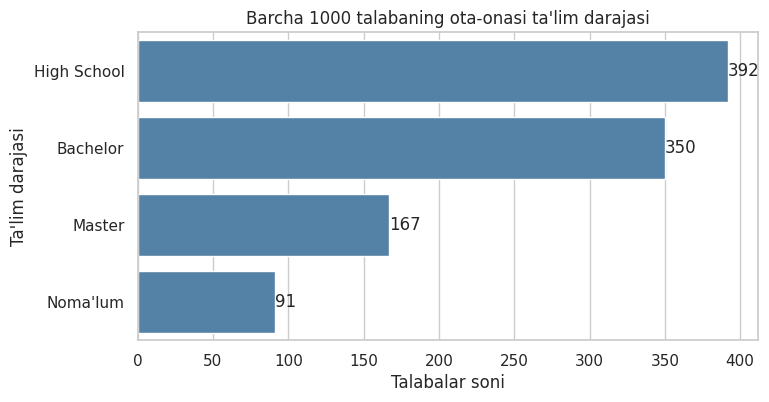

In [125]:
# 1) bo'sh qiymatlarni to'ldiring
# 2) grafikni qayta chizing (Mashq 7.1 dagidek)
talaba['ota_ona_talimi'] = talaba[
    'ota_ona_talimi'
].fillna("Noma'lum")

fig, ax = plt.subplots()

tartib = talaba['ota_ona_talimi'].value_counts().index

sns.countplot(
    data=talaba,
    y='ota_ona_talimi',
    order=tartib,
    color='steelblue',
    ax=ax
)

for container in ax.containers:
    ax.bar_label(container)

ax.set_title("Barcha 1000 talabaning ota-onasi ta'lim darajasi")
ax.set_xlabel("Talabalar soni")
ax.set_ylabel("Ta'lim darajasi")

plt.show()

In [126]:
# ✅ Tekshirish
assert talaba['ota_ona_talimi'].isna().sum() == 0, "Bo'sh qiymatlar qolmasligi kerak: fillna(\"Noma'lum\")"
w = [p.get_width() for p in ax.patches]
assert w == [392, 350, 167, 91], f"Ustun uzunliklari [392, 350, 167, 91] bo'lishi kerak, sizda: {w}"
assert sum(w) == 1000, "Yig'indi 1000 bo'lishi kerak"
print("To'g'ri! 👍  Endi barcha 1000 talaba hisobga olingan.")

To'g'ri! 👍  Endi barcha 1000 talaba hisobga olingan.


### 🔹 Mashq 7.3
Ruhiy holat bahosi (`ruhiy_holat`, 1–10) bo'yicha **o'rtacha ball** trendini `pointplot` bilan chizing (95% ishonch oralig'i bilan, `errorbar=('ci', 95)`, `capsize=0.2`).

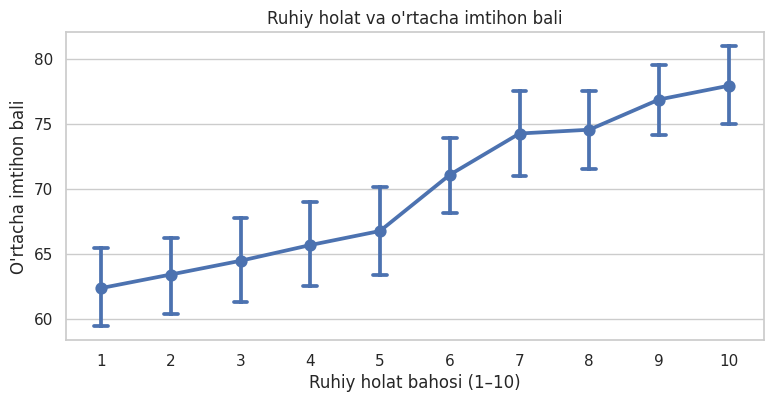

In [127]:
# Kodingizni shu yerga yozing
fig, ax = plt.subplots(figsize=(9, 4))

sns.pointplot(
    data=talaba,
    x='ruhiy_holat',
    y='ball',
    errorbar=('ci', 95),
    capsize=0.2,
    ax=ax
)

ax.set_title("Ruhiy holat va o'rtacha imtihon bali")
ax.set_xlabel("Ruhiy holat bahosi (1–10)")
ax.set_ylabel("O'rtacha imtihon bali")

plt.show()

In [128]:
# ✅ Tekshirish
asosiy = [l for l in ax.lines if len(l.get_xdata()) == 10]
assert len(asosiy) >= 1, "10 ta nuqtali chiziq topilmadi: sns.pointplot(x='ruhiy_holat', y='ball', ..., ax=ax)"
yv = [round(float(v), 2) for v in asosiy[0].get_ydata()]
assert yv == [62.37, 63.42, 64.48, 65.69, 66.77, 71.09, 74.27, 74.57, 76.89, 77.95], f"O'rtachalar noto'g'ri: {yv}"
print("To'g'ri! 👍")

To'g'ri! 👍


### 🔍 Mashq 7.4 — grafikni o'qing
Ishonch oralig'i chiziqlari ustma-ust tushsa — farq **ishonchsiz** (`False`), tushmasa — **ishonchli** (`True`).
- `javob_7a` — ruhiy holat **1** va **2** o'rtasidagi farq ishonchlimi?
- `javob_7b` — ruhiy holat **1** va **10** o'rtasidagi farq ishonchlimi?

In [129]:
javob_7a = False
javob_7b = True

print("1 va 2 orasidagi farq:", javob_7a)
print("1 va 10 orasidagi farq:", javob_7b)

1 va 2 orasidagi farq: False
1 va 10 orasidagi farq: True


In [130]:
# ✅ Tekshirish
assert javob_7a is False, "1 va 2 ustidagi vertikal chiziqlar kesishadimi?"
assert javob_7b is True, "1 va 10 ustidagi chiziqlar orasida bo'shliq bormi?"
print("To'g'ri! 👍  Qo'shni baholar farqi tasodif bo'lishi mumkin, lekin chekka baholar (1 va 10) orasidagi farq aniq.")

To'g'ri! 👍  Qo'shni baholar farqi tasodif bo'lishi mumkin, lekin chekka baholar (1 va 10) orasidagi farq aniq.


---
## 8. Panellar: `catplot` va `displot` 🆕

`catplot` — kategoriyalar uchun **figure-level** funksiya: `kind=` bilan grafik turini (`box`, `bar`, `count`, `violin`, `point`…), `col=` / `row=` bilan panellarni tanlaysiz.

`displot` — **taqsimot** (`histplot`, `kdeplot`) uchun xuddi shunday figure-level funksiya: `kind='hist'`, `'kde'` yoki `'ecdf'`, va `col=` / `row=` / `hue=`.

Ikkalasi ham o'z rasmini yaratadi, shuning uchun `ax=` qabul qilmaydi; natija — `g` obyekti.

### 📘 Namuna 8

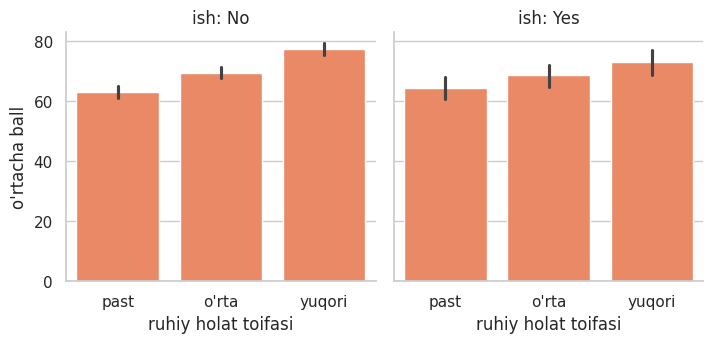

In [131]:
g = sns.catplot(data=talaba, x='ruhiy_toifa', y='ball', kind='bar', col='ish', height=3.6, color='coral')
g.set_axis_labels('ruhiy holat toifasi', "o'rtacha ball")
g.set_titles('ish: {col_name}')
plt.show()

### 🔹 Mashq 8.1
`catplot` bilan **sanash** grafigini chizing: `x='ovqat'`, `kind='count'`, panellar — `col='togarak'`, tartib — `order=['Poor', 'Fair', 'Good']`.
Natijani `g1` ga saqlang.

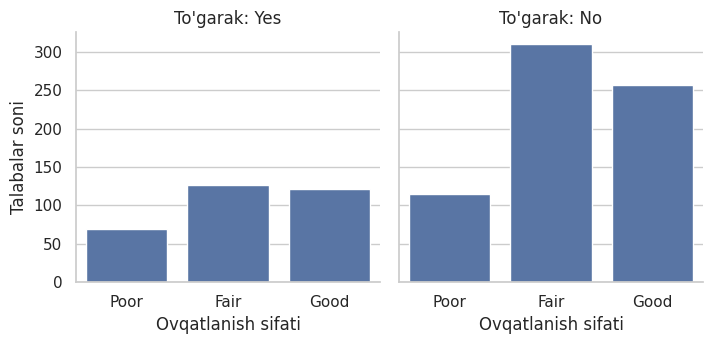

In [132]:
g1 = sns.catplot(
    data=talaba,
    x='ovqat',
    kind='count',
    col='togarak',
    order=['Poor', 'Fair', 'Good'],
    height=3.6
)

g1.set_axis_labels("Ovqatlanish sifati", "Talabalar soni")
g1.set_titles("To'garak: {col_name}")

plt.show()

In [133]:
# ✅ Tekshirish
assert g1.axes.shape == (1, 2), "col='togarak' -> 2 ta panel"
jami = sum(p.get_height() for a in g1.axes.flat for p in a.patches)
assert jami == 1000, f"Barcha ustunlar yig'indisi 1000 talabaga teng bo'lishi kerak, sizda: {jami}"
print("To'g'ri! 👍")

To'g'ri! 👍


### 🔹 Mashq 8.2
`displot` bilan `oqish_soati` histogrammasini **internet sifati** bo'yicha panellarda chizing:
`kind='hist'`, `bins=15`, `kde=True`, `col='internet'`, `col_order=['Poor', 'Average', 'Good']`, `height=3.3`. Natijani `g2` ga saqlang.

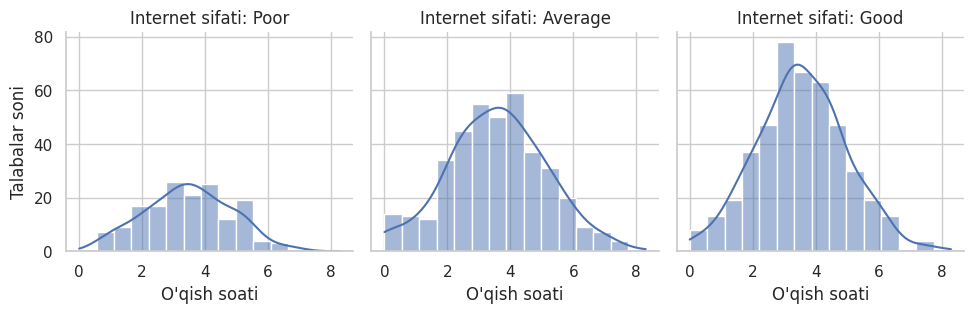

In [134]:
g2 = sns.displot(
    data=talaba,
    x='oqish_soati',
    kind='hist',
    bins=15,
    kde=True,
    col='internet',
    col_order=['Poor', 'Average', 'Good'],
    height=3.3
)

g2.set_axis_labels("O'qish soati", "Talabalar soni")
g2.set_titles("Internet sifati: {col_name}")

plt.show()

In [135]:
# ✅ Tekshirish
assert g2.axes.shape == (1, 3), "col='internet' -> 3 ta panel"
for a in g2.axes.flat:
    assert len(a.patches) == 15, f"Har panelda 15 ta ustun bo'lishi kerak, sizda: {len(a.patches)}"
print("To'g'ri! 👍")

To'g'ri! 👍


### 🔍 Mashq 8.3 — grafikni o'qing
Namuna 8 dagi ikki panelga qarang (ishonch oralig'i chiziqlari ustma-ust tushsa — farq ishonchsiz).
- `javob_8a` — `ish: No` panelida **past** va **yuqori** ruhiy toifalar orasidagi farq ishonchlimi?
- `javob_8b` — `ish: Yes` panelida **past** va **o'rta** ruhiy toifalar orasidagi farq ishonchlimi?

In [136]:
javob_8a = True
javob_8b = False

print("Ishlamaydigan talabalar:", javob_8a)
print("Ishlaydigan talabalar:", javob_8b)

Ishlamaydigan talabalar: True
Ishlaydigan talabalar: False


In [137]:
# ✅ Tekshirish
assert javob_8a is True, "Chap panelda birinchi va uchinchi ustun ustidagi qora chiziqlar kesishadimi?"
assert javob_8b is False, "O'ng panelda ishlaydiganlar kam (215 ta) — oraliqlar keng, birinchi ikki ustun ustma-ust tushadi"
print("To'g'ri! 👍  Guruh kichik bo'lsa oraliq keng bo'ladi: ishlaydiganlarda (n=215) farqni ishonch bilan aytish qiyinroq.")

To'g'ri! 👍  Guruh kichik bo'lsa oraliq keng bo'ladi: ishlaydiganlarda (n=215) farqni ishonch bilan aytish qiyinroq.


---
## 9. Mini-loyiha: qaysi odat imtihon ballini eng ko'p belgilaydi?

Universitet rahbariyati so'raydi: **talabalarga qaysi odatni o'zgartirishni maslahat berish kerak?**
Quyidagi ma'lumotlar bilan javob bering. Avval ma'lumotni tayyorlaymiz: `ball` bilan korrelyatsiya va uyqu toifalari.

In [138]:
r = talaba[sonli].corr()['ball'].drop('ball').sort_values()    # ball bilan korrelyatsiya, o'sish tartibida
talaba['uyqu_toifa'] = pd.cut(talaba['uyqu'], bins=[0, 6, 8, 24], labels=['kam (<=6)', 'normal (6-8)', "ko'p (>8)"])
print(r.round(2).to_dict())
print(talaba['uyqu_toifa'].value_counts().sort_index().to_dict())

{'netflix': -0.17, 'ijtimoiy_tarmoq': -0.17, 'yosh': -0.01, 'davomat': 0.09, 'uyqu': 0.12, 'sport': 0.16, 'ruhiy_holat': 0.32, 'oqish_soati': 0.83}
{'kam (<=6)': 368, 'normal (6-8)': 529, "ko'p (>8)": 103}


### 🔹 Topshiriq 9 (erkin, avtomatik tekshirilmaydi)
1. **barplot**: `r` dagi korrelyatsiyalar (`x=r.values`, `y=r.index`) — qaysi odat eng muhim, qaysilari ballga deyarli ta'sir qilmaydi? `ax.axvline(0)` qo'shing.
2. **regplot**: ballga eng kuchli ta'sir qiluvchi ikki odat (`oqish_soati` va `ruhiy_holat`) uchun yonma-yon ikki regressiya grafigi. Ikkinchisida `x_jitter=0.2` ni sinab ko'ring (nega kerak?).
3. **violin** (+ `swarmplot` namuna ustiga): `uyqu_toifa` bo'yicha `ball`, `cut=0`. Kam uxlaganlar farq qiladimi? Qaysi toifada kuzatuv kam (violin ishonchsizroq)?
4. **pointplot**: `sport` (0–6) bo'yicha o'rtacha ball, `hue='ish'` bilan, 95% CI. Trend bormi? Ishlaydiganlar va ishlamaydiganlar farqi ishonchlimi?
5. To'rttasini `plt.subplots(2, 2, figsize=(13, 9))` bilan bitta rasmga joylang, har biriga xulosa-sarlavha bering.
6. Pastdagi katakchaga universitet rahbariyati uchun **3 jumlalik xulosa** yozing. Eslatma: bu kuzatuv ma'lumoti — odat ballni **oshirdi** deb aytib bo'lmaydi, faqat **bog'liqlik** bor.

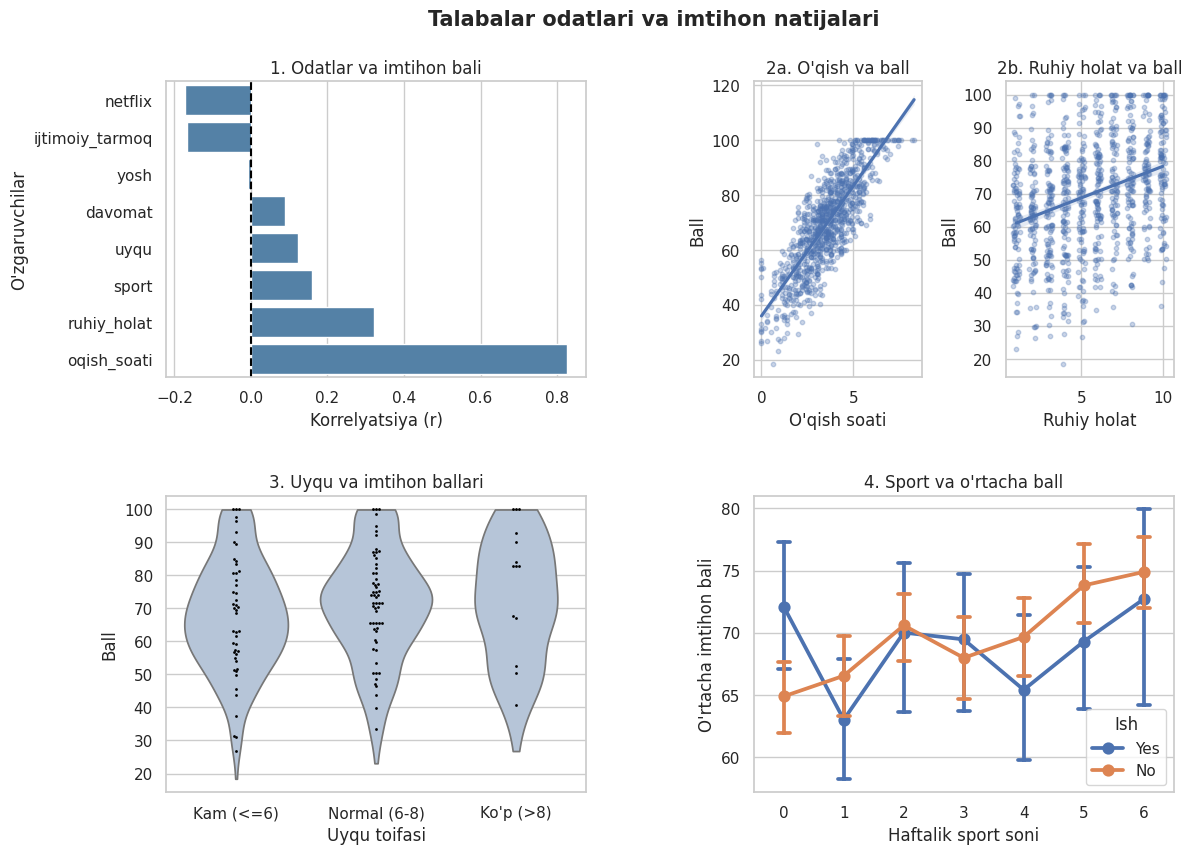

Grafiklar chizildi!
BALL BILAN KORRELYATSIYALAR:
netflix           -0.172
ijtimoiy_tarmoq   -0.167
yosh              -0.009
davomat            0.090
uyqu               0.122
sport              0.160
ruhiy_holat        0.322
oqish_soati        0.825
Name: ball, dtype: float64

UYQU TOIFALARI:
uyqu_toifa
Normal (6-8)    529
Kam (<=6)       368
Ko'p (>8)       103
Name: count, dtype: int64

UYQU TOIFALARI BO'YICHA O'RTACHA BALL:
uyqu_toifa
Kam (<=6)       67.65
Normal (6-8)    70.60
Ko'p (>8)       71.43
Name: ball, dtype: float64

SPORT BO'YICHA O'RTACHA BALL:
sport
0    66.38
1    65.81
2    70.46
3    68.38
4    68.73
5    72.71
6    74.57
Name: ball, dtype: float64

Eng kuchli musbat korrelyatsiya:
oqish_soati 0.825


In [139]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

# 1. Ma'lumotlarni tayyorlash
sonli = [
    'yosh',
    'oqish_soati',
    'ijtimoiy_tarmoq',
    'netflix',
    'davomat',
    'uyqu',
    'sport',
    'ruhiy_holat',
    'ball'
]

# Ball bilan korrelyatsiyalar
r = (
    talaba[sonli]
    .corr()['ball']
    .drop('ball')
    .sort_values()
)

# Uyqu toifalarini yaratish
talaba['uyqu_toifa'] = pd.cut(
    talaba['uyqu'],
    bins=[0, 6, 8, 24],
    labels=[
        'Kam (<=6)',
        'Normal (6-8)',
        "Ko'p (>8)"
    ]
)

# Swarmplot uchun 120 ta talaba
kichik_uyqu = talaba.sample(
    n=120,
    random_state=3
)

# 2. Asosiy 2x2 grafik
fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 9)
)

# =====================================
# 1-GRAFIK: Korrelyatsiya barplot
# =====================================

sns.barplot(
    x=r.values,
    y=r.index,
    color='steelblue',
    ax=axes[0, 0]
)

axes[0, 0].axvline(
    0,
    color='black',
    linestyle='--'
)

axes[0, 0].set_title(
    "1. Odatlar va imtihon bali"
)

axes[0, 0].set_xlabel("Korrelyatsiya (r)")
axes[0, 0].set_ylabel("O'zgaruvchilar")


# =====================================
# 2-GRAFIK: Ikkita regressiya
# =====================================

# Yuqori o'ng panelni ikkiga ajratish
joy = axes[0, 1].get_subplotspec()
axes[0, 1].remove()

ichki = joy.subgridspec(
    1, 2,
    wspace=0.5
)

ax1 = fig.add_subplot(ichki[0, 0])
ax2 = fig.add_subplot(ichki[0, 1])

# O'qish soati va ball
sns.regplot(
    data=talaba,
    x='oqish_soati',
    y='ball',
    scatter_kws={
        'alpha': 0.3,
        's': 10
    },
    ax=ax1
)

ax1.set_title("2a. O'qish va ball")
ax1.set_xlabel("O'qish soati")
ax1.set_ylabel("Ball")

# Ruhiy holat va ball
sns.regplot(
    data=talaba,
    x='ruhiy_holat',
    y='ball',
    x_jitter=0.2,
    scatter_kws={
        'alpha': 0.3,
        's': 10
    },
    ax=ax2
)

ax2.set_title("2b. Ruhiy holat va ball")
ax2.set_xlabel("Ruhiy holat")
ax2.set_ylabel("Ball")


# =====================================
# 3-GRAFIK: Violin + Swarmplot
# =====================================

sns.violinplot(
    data=talaba,
    x='uyqu_toifa',
    y='ball',
    inner=None,
    cut=0,
    color='lightsteelblue',
    ax=axes[1, 0]
)

sns.swarmplot(
    data=kichik_uyqu,
    x='uyqu_toifa',
    y='ball',
    color='black',
    size=2,
    ax=axes[1, 0]
)

axes[1, 0].set_title(
    "3. Uyqu va imtihon ballari"
)

axes[1, 0].set_xlabel("Uyqu toifasi")
axes[1, 0].set_ylabel("Ball")


# =====================================
# 4-GRAFIK: Sport va o'rtacha ball
# =====================================

sns.pointplot(
    data=talaba,
    x='sport',
    y='ball',
    hue='ish',
    errorbar=('ci', 95),
    capsize=0.2,
    ax=axes[1, 1]
)

axes[1, 1].set_title(
    "4. Sport va o'rtacha ball"
)

axes[1, 1].set_xlabel(
    "Haftalik sport soni"
)

axes[1, 1].set_ylabel(
    "O'rtacha imtihon bali"
)

axes[1, 1].legend(title="Ish")


# =====================================
# YAKUNIY RASM
# =====================================

fig.suptitle(
    "Talabalar odatlari va imtihon natijalari",
    fontsize=15,
    fontweight='bold'
)

plt.subplots_adjust(
    hspace=0.4,
    wspace=0.4,
    top=0.90
)

plt.show()

print("Grafiklar chizildi!")
print("BALL BILAN KORRELYATSIYALAR:")
print(r.round(3))

print("\nUYQU TOIFALARI:")
print(talaba['uyqu_toifa'].value_counts())

print("\nUYQU TOIFALARI BO'YICHA O'RTACHA BALL:")
print(
    talaba.groupby(
        'uyqu_toifa',
        observed=True
    )['ball'].mean().round(2)
)

print("\nSPORT BO'YICHA O'RTACHA BALL:")
print(
    talaba.groupby('sport')['ball'].mean().round(2)
)

print("\nEng kuchli musbat korrelyatsiya:")
print(r.idxmax(), round(r.max(), 3))

✍️ **Xulosa:** *(3 jumla)* Tahlil natijalarida kunlik o‘qish soati imtihon ballari bilan eng kuchli musbat korrelyatsiyaga ega ekanligi kuzatildi.

Ruhiy holat bahosi ham imtihon natijalari bilan musbat bog‘langan, ijtimoiy tarmoq va Netflix uchun sarflangan vaqt esa manfiy bog‘liqlik ko‘rsatdi.

Universitet rahbariyatiga talabalarning o‘qish vaqtini rejalashtirishini va ruhiy farovonligini qo‘llab-quvvatlash tavsiya etiladi, biroq bu kuzatuvlar sabab-oqibatni isbotlamaydi.

---
## Yakun: qaysi savolga qaysi grafik

| Savol | Seaborn |
|---|---|
| Bitta o'zgaruvchi qanday taqsimlangan? | `histplot`, `kdeplot` |
| Guruhlar taqsimoti (median, tarqoqlik, outlier) | `boxplot` |
| Taqsimot shakli, cho'qqilar | `violinplot` (`cut=0`) |
| Har bir kuzatuvni ko'rsatish (kam ma'lumot) | `swarmplot`, `stripplot` |
| Ikki sonli o'zgaruvchi orasidagi bog'liqlik | `scatterplot`, `regplot`, `lmplot` |
| Ko'p ustun orasidagi bog'liqlik (raqam) | `heatmap(corr, center=0)` |
| Ko'p ustun orasidagi bog'liqlik (shakl) | `pairplot` |
| Nechta? (sanash) | `countplot` |
| O'rtacha va uning ishonchliligi | `barplot`, `pointplot` (tartiblangan guruhlar uchun) |
| Bir xil grafik — bir necha panelda | `catplot(kind=..., col=...)`, `displot(col=...)` |

**Eng ko'p uchraydigan xatolar:** keng jadvalni seabornga berish (`melt` kerak) · whiskerni min/max deb o'qish ·
`catplot`/`displot`/`lmplot`ga `ax=` berish · korrelyatsiya heatmapida ketma-ket palitra · kam kuzatuvda violin chizish ·
**bo'sh qiymatlarni (`NaN`) tekshirmaslik** — seaborn ularni jimgina tashlaydi · chegarali qiymatda `cut=0` ni unutish ·
1000+ nuqtada `swarmplot` ishlatish · korrelyatsiyani sabab-oqibat deb o'qish.